# Phase II Assignment
### Hank Eichstaedt

- Motivation
- Methods
- Results
- Discussion

## Setting up

Libraries and gathering our larger data sets

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
player_play = pd.read_csv("data/player_play.csv")
game_tracking_2023 = pd.read_csv("data/game_tracking_2023.csv")
combine_results = pd.read_csv("data/combine_results.csv")

### Note

Here I am only collecting data from 2023. This will make my data set smaller as I am missing two years. This is simply for the start of Phase II as I work through, later projects will have more data

# Concept One: Force

Sir Isaac Newton invented the force equation, `F = m * a` when he coined his Second Law of Motion. Who am I to say this isn't a viable metric for measuring offensive linemen?

In [12]:
oline = combine_results.loc[
    (combine_results['combine_position'] == 'OL'),
    ['nfl_id', 'combine_weight']
]

oline['weight'] = oline['combine_weight'] / 2.20462 # Convert to kg

In [32]:
passing = player_play.loc[
    (player_play['lined_up_position'] == 'T') |
    (player_play['lined_up_position'] == 'G') |
    (player_play['lined_up_position'] == 'C'),
    ['game_id', 'play_id', 'nfl_id', 'lined_up_position', 'pass_result']
]

passing = passing[passing['pass_result'].notna()]

passing = passing.drop_duplicates(
    subset=['game_id', 'play_id', 'nfl_id']
) # Make sure no duplicate values

In [20]:
oline_tracking = game_tracking_2023.merge(
    oline[['nfl_id', 'weight']],
    on='nfl_id',
    how='inner'
)

# This gives us 37 OL from the 2023 season

Sort by game, play, and time so all plays are in a row based on who we are tracking

In [21]:
oline_tracking = oline_tracking.sort_values(
    ['game_id', 'play_id', 'time']
).copy()

In [23]:
oline_tracking['row_num'] = (
    oline_tracking.groupby(['game_id', 'play_id']).cumcount()
)

# identify when snap occurs
snap_rows = (
    oline_tracking[oline_tracking['event'] == 'ball_snap']
    [['game_id', 'play_id', 'row_num']]
    .rename(columns={'row_num': 'snap_row'})
)

oline_tracking = oline_tracking.merge(
    snap_rows,
    on=['game_id', 'play_id'],
    how='left'
)

We are looking at the first three seconds for this df

In [25]:
first_three = oline_tracking[
    oline_tracking['row_num'].between(
        oline_tracking['snap_row'],
        oline_tracking['snap_row'] + 30
    )
].copy()

In [28]:
first_three = first_three.merge(
    passing[['game_id', 'play_id', 'nfl_id']],
    on=['game_id', 'play_id', 'nfl_id'],
    how='inner'
)

In [34]:
first_three['seconds_after_snap'] = (
    first_three['row_num'] - first_three['snap_row']
) * 0.1

In [40]:
time_groups = [1.0, 1.5, 2.0, 2.5, 3.0]

average_acceleration = []

for nfl_id, player_data in first_three.groupby('nfl_id'):

    for seconds in time_groups:

        group = player_data[
            player_data['seconds_after_snap'] <= seconds
        ]

        average_acceleration.append({
            'nfl_id': nfl_id,
            'Time Interval': f'0.0 - {seconds}',
            'Average Acceleration': group['a'].mean()
        })

average_acceleration_df = pd.DataFrame(average_acceleration)

In [46]:
average_acceleration_df = average_acceleration_df.merge(
    first_three[['nfl_id', 'weight']].drop_duplicates('nfl_id'),
    on='nfl_id',
    how='left'
)

In [48]:
average_acceleration_df['Force'] = (
    average_acceleration_df['Average Acceleration'] *
    average_acceleration_df['weight']
)

In [49]:
display(average_acceleration_df)

,nfl_id,Time Interval,Average Acceleration,weight,Force
0,55870,0.0 - 1.0,1.280815,141.974581,181.843141
1,55870,0.0 - 1.5,1.306912,141.974581,185.548272
2,55870,0.0 - 2.0,1.362772,141.974581,193.479046
3,55870,0.0 - 2.5,1.460420,141.974581,207.342473
4,55870,0.0 - 3.0,1.556020,141.974581,220.915340
...,...,...,...,...,...
180,56645,0.0 - 1.0,1.299506,145.149731,188.622886
181,56645,0.0 - 1.5,1.289627,145.149731,187.189040
182,56645,0.0 - 2.0,1.345565,145.149731,195.308377
183,56645,0.0 - 2.5,1.400522,145.149731,203.285397


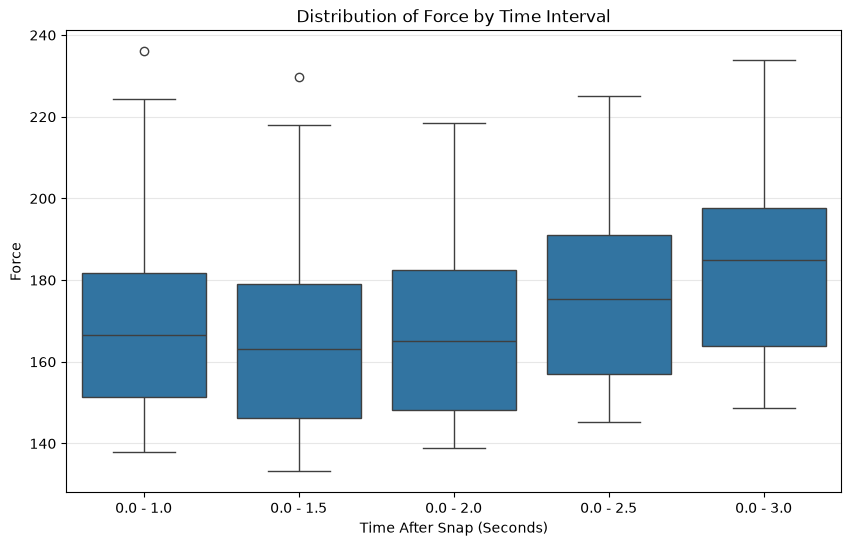

In [51]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=average_acceleration_df,
    x='Time Interval',
    y='Force'
)

plt.title('Distribution of Force by Time Interval')
plt.xlabel('Time After Snap (Seconds)')
plt.ylabel('Force')
plt.grid(axis='y', alpha=0.3)

plt.show()